# 🧬 Cancer Mortality Rate Regression Project

## Project Overview
This project aims to predict cancer mortality rates across different US counties using a variety of socio-economic and demographic features. The workflow leverages data science and machine learning techniques to build, evaluate, and tune regression models for accurate predictions.

## Workflow Summary
- **Data Sources:**
  - `cancer_reg.csv`: Contains cancer statistics and related features by geography.
  - `avg-household-size.csv`: Provides average household size by geography.
- **Data Preparation:**
  - Merge datasets on the `geography` column.
  - Handle missing values and drop columns with excessive missing data.
  - Impute remaining missing values and remove irrelevant/categorical columns.
- **Exploratory Data Analysis (EDA):**
  - Overview of data structure and missing values.
  - Visualize target variable distribution and feature correlations.
  - Identify top features correlated with cancer death rates.
- **Feature Engineering:**
  - Scale features using `StandardScaler`.
  - Prepare features (`X`) and target (`y`).
- **Modeling:**
  - Train/test split using `train_test_split`.
  - Train multiple regression models: `LinearRegression`, `Ridge`, `Lasso`, `ElasticNet`, `RandomForestRegressor`, `GradientBoostingRegressor`.
  - Evaluate models using `R2`, `RMSE`, and `MAE` metrics.
- **Model Tuning:**
  - Hyperparameter optimization for the best model (e.g., `RandomForestRegressor`) using `GridSearchCV`.

## Key Takeaways
- The notebook demonstrates a full machine learning pipeline for regression tasks.
- Emphasizes data cleaning, feature selection, and model evaluation.
- Provides a template for similar predictive analytics projects in public health or other domains.

---

*For details, refer to the code cells and markdown explanations throughout the notebook.*

### **Step 1: Import Libraries**
- Import essential libraries like `numpy`, `pandas`, `matplotlib`, `seaborn`, and scikit-learn modules.
- Use `warnings.filterwarnings('ignore')` and `plt.style.use('seaborn-v0_8')` for a clean workflow.

In [1]:
# 1. Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8')

### **Step 2: Load and Merge Datasets**
- Load datasets using `pd.read_csv`.
- Merge on the `geography` column to enrich the data.

In [2]:
# 2. Load and Merge Datasets
df_cancer = pd.read_csv('dataset/cancer_reg.csv')
df_household = pd.read_csv('dataset/avg-household-size.csv')

# Merge on 'geography'
df = pd.merge(df_cancer, df_household[['geography', 'avghouseholdsize']], on='geography', how='left')
print('Merged shape:', df.shape)
df.head()

Merged shape: (3047, 34)


,avganncount,avgdeathsperyear,target_deathrate,incidencerate,medincome,popest2015,povertypercent,studypercap,binnedinc,medianage,...,pctempprivcoverage,pctpubliccoverage,pctpubliccoveragealone,pctwhite,pctblack,pctasian,pctotherrace,pctmarriedhouseholds,birthrate,avghouseholdsize
0,1397.0,469,164.9,489.8,61898,260131,11.2,499.748204,"(61494.5, 125635]",39.3,...,41.6,32.9,14.0,81.780529,2.594728,4.821857,1.843479,52.856076,6.118831,2.54
1,173.0,70,161.3,411.6,48127,43269,18.6,23.111234,"(48021.6, 51046.4]",33.0,...,43.6,31.1,15.3,89.228509,0.969102,2.246233,3.741352,45.372500,4.333096,2.34
2,102.0,50,174.7,349.7,49348,21026,14.6,47.560164,"(48021.6, 51046.4]",45.0,...,34.9,42.1,21.1,90.922190,0.739673,0.465898,2.747358,54.444868,3.729488,2.62
3,427.0,202,194.8,430.4,44243,75882,17.1,342.637253,"(42724.4, 45201]",42.8,...,35.0,45.3,25.0,91.744686,0.782626,1.161359,1.362643,51.021514,4.603841,2.52
4,57.0,26,144.4,350.1,49955,10321,12.5,0.000000,"(48021.6, 51046.4]",48.3,...,35.1,44.0,22.7,94.104024,0.270192,0.665830,0.492135,54.027460,6.796657,2.34


### **Step 3: Data Overview & Missing Values**
- Use `df.info()` and `df.describe()` for a quick overview.
- Check missing values with `df.isnull().sum()`.
- Visualize missing data using `sns.heatmap`.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3047 entries, 0 to 3046
Data columns (total 34 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   avganncount              3047 non-null   float64
 1   avgdeathsperyear         3047 non-null   int64  
 2   target_deathrate         3047 non-null   float64
 3   incidencerate            3047 non-null   float64
 4   medincome                3047 non-null   int64  
 5   popest2015               3047 non-null   int64  
 6   povertypercent           3047 non-null   float64
 7   studypercap              3047 non-null   float64
 8   binnedinc                3047 non-null   object 
 9   medianage                3047 non-null   float64
 10  medianagemale            3047 non-null   float64
 11  medianagefemale          3047 non-null   float64
 12  geography                3047 non-null   object 
 13  percentmarried           3047 non-null   float64
 14  pctnohs18_24            

None

,avganncount,avgdeathsperyear,target_deathrate,incidencerate,medincome,popest2015,povertypercent,studypercap,medianage,medianagemale,...,pctempprivcoverage,pctpubliccoverage,pctpubliccoveragealone,pctwhite,pctblack,pctasian,pctotherrace,pctmarriedhouseholds,birthrate,avghouseholdsize
count,3047.000000,3047.000000,3047.000000,3047.000000,3047.000000,3.047000e+03,3047.000000,3047.000000,3047.000000,3047.000000,...,3047.000000,3047.000000,3047.000000,3047.000000,3047.000000,3047.000000,3047.000000,3047.000000,3047.000000,3047.000000
mean,606.338544,185.965868,178.664063,448.268586,47063.281917,1.026374e+05,16.878175,155.399415,45.272333,39.570725,...,41.196324,36.252642,19.240072,83.645286,9.107978,1.253965,1.983523,51.243872,5.640306,2.529682
std,1416.356223,504.134286,27.751511,54.560733,12040.090836,3.290592e+05,6.409087,529.628366,45.304480,5.226017,...,9.447687,7.841741,6.113041,16.380025,14.534538,2.610276,3.517710,6.572814,1.985816,0.248449
min,6.000000,3.000000,59.700000,201.300000,22640.000000,8.270000e+02,3.200000,0.000000,22.300000,22.400000,...,13.500000,11.200000,2.600000,10.199155,0.000000,0.000000,0.000000,22.992490,0.000000,1.860000
25%,76.000000,28.000000,161.200000,420.300000,38882.500000,1.168400e+04,12.150000,0.000000,37.700000,36.350000,...,34.500000,30.900000,14.850000,77.296180,0.620675,0.254199,0.295172,47.763063,4.521419,2.380000
50%,171.000000,61.000000,178.100000,453.549422,45207.000000,2.664300e+04,15.900000,0.000000,41.000000,39.600000,...,41.100000,36.300000,18.800000,90.059774,2.247576,0.549812,0.826185,51.669941,5.381478,2.500000
75%,518.000000,149.000000,195.200000,480.850000,52492.000000,6.867100e+04,20.400000,83.650776,44.000000,42.500000,...,47.700000,41.550000,23.100000,95.451693,10.509732,1.221037,2.177960,55.395132,6.493677,2.640000
max,38150.000000,14010.000000,362.800000,1206.900000,125635.000000,1.017029e+07,47.400000,9762.308998,624.000000,64.700000,...,70.700000,65.100000,46.600000,100.000000,85.947799,42.619425,41.930251,78.075397,21.326165,3.970000


Missing values:
pctsomecol18_24            2285
pctprivatecoveragealone     609
pctemployed16_over          152
dtype: int64


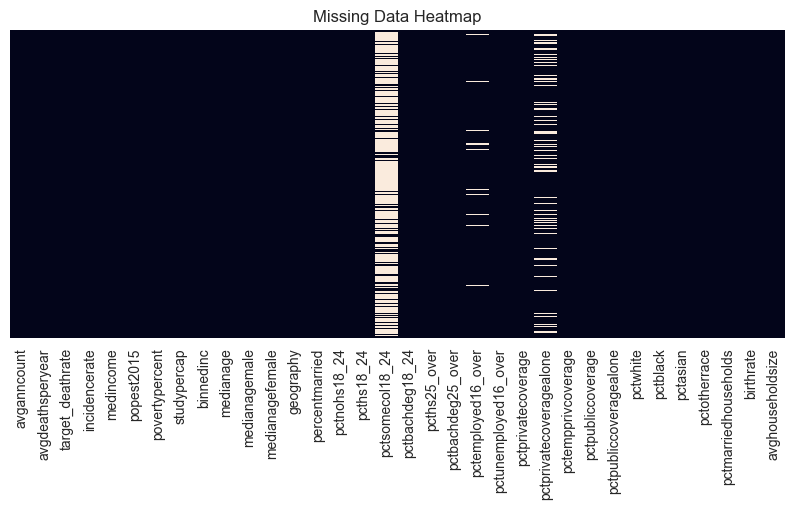

In [3]:
# Data overview
display(df.info())
display(df.describe())

# Missing values
missing = df.isnull().sum().sort_values(ascending=False)
print('Missing values:')
print(missing[missing > 0])

# Visualize missing data
plt.figure(figsize=(10,4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title('Missing Data Heatmap')
plt.show()

### **Step 4: Target Distribution**
- Visualize the distribution of `target_deathrate` using `sns.histplot`.
- Check for skewness and spread.

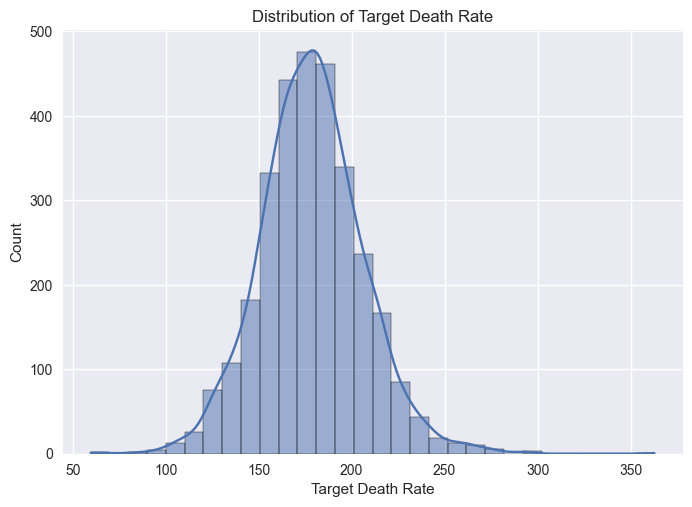

In [4]:
# Distribution of target
sns.histplot(df['target_deathrate'], kde=True, bins=30)
plt.title('Distribution of Target Death Rate')
plt.xlabel('Target Death Rate')
plt.show()

### **Step 5: Correlation Analysis**
- Use `df.corr()` to explore correlations.
- Visualize with `sns.heatmap`.

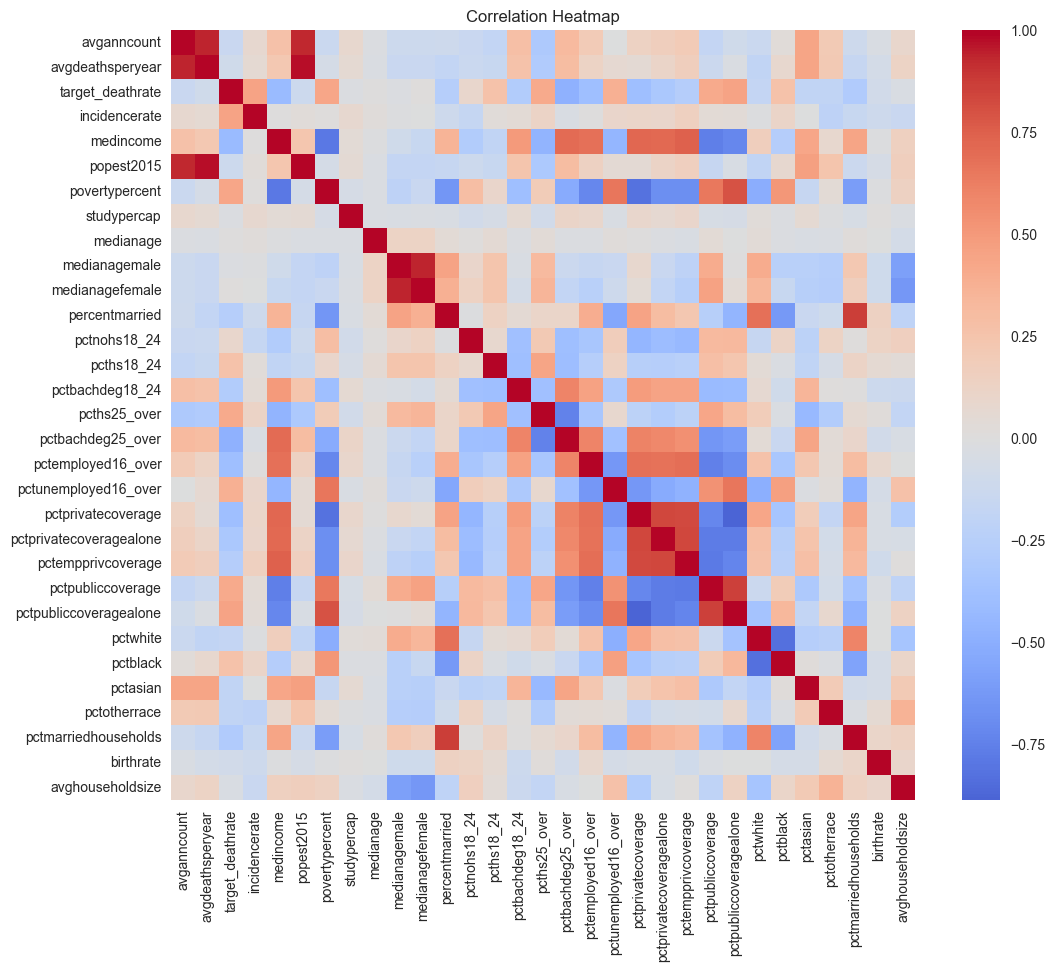

In [20]:
# Correlation heatmap
plt.figure(figsize=(12,10))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=False, cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.show()

### **Step 6: Top Correlated Features**
- Identify top features correlated with `target_deathrate`.
- Visualize each with `sns.scatterplot`.

Top correlated features:
pctbachdeg25_over         0.485477
incidencerate             0.449432
pctpubliccoveragealone    0.449358
povertypercent            0.429389
medincome                 0.428615
pctemployed16_over        0.412046
pcths25_over              0.404589
pctpubliccoverage         0.404572
pctprivatecoverage        0.386066
pctunemployed16_over      0.378412
Name: target_deathrate, dtype: float64


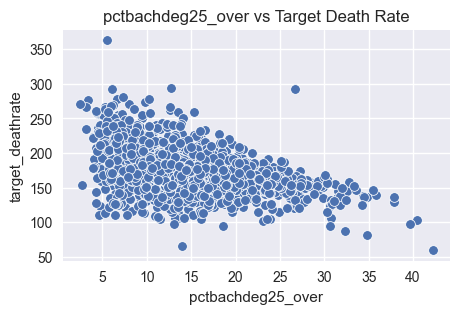

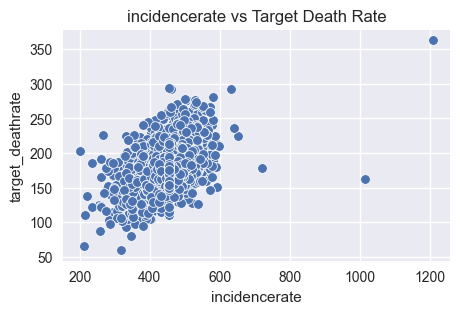

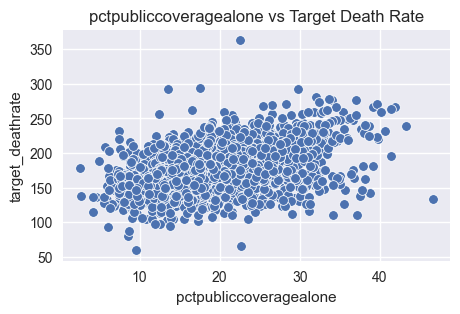

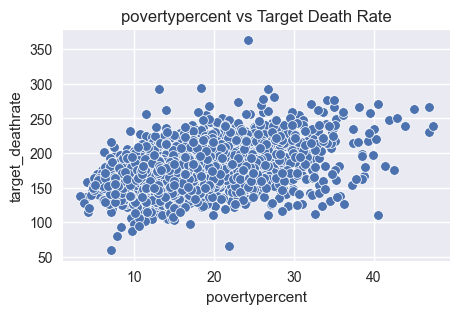

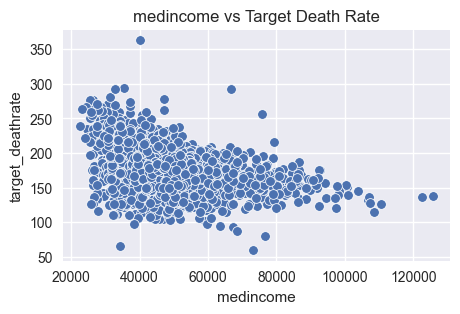

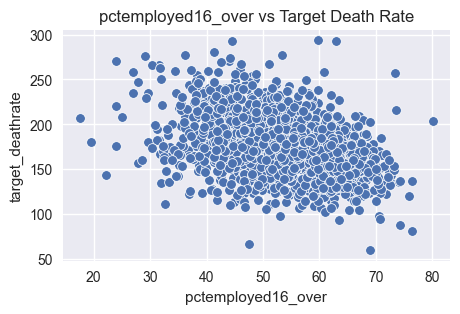

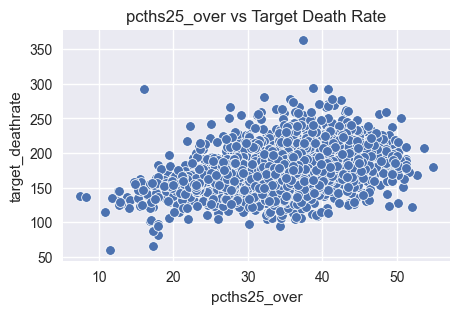

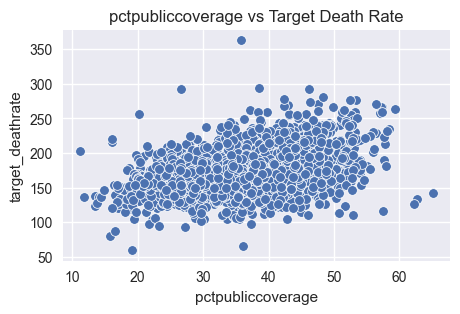

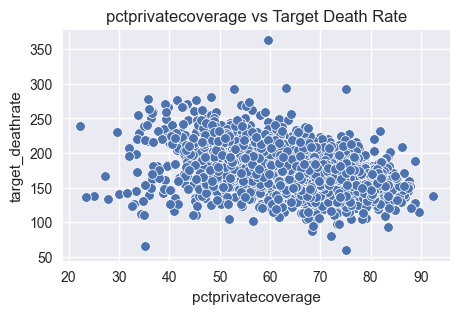

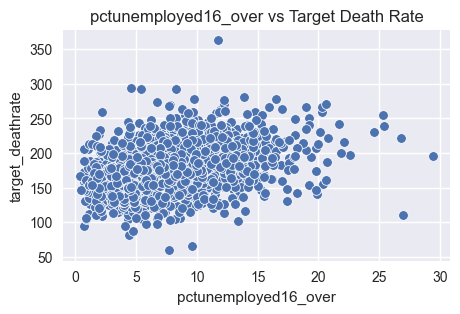

In [6]:
# Top correlated features with target
top_corr = corr['target_deathrate'].abs().sort_values(ascending=False)[1:11]
print('Top correlated features:')
print(top_corr)

# Visualize top features
for col in top_corr.index:
    plt.figure(figsize=(5,3))
    sns.scatterplot(x=df[col], y=df['target_deathrate'])
    plt.title(f'{col} vs Target Death Rate')
    plt.show()

### **Step 7: Handle Missing Data**
- Drop columns with more than 50% missing values using a threshold.
- Use `df.drop(columns=drop_cols)` to clean the data.

In [7]:
# Drop columns with more than 50% missing values
threshold = len(df) * 0.5
drop_cols = [col for col in df.columns if df[col].isnull().sum() > threshold]
df = df.drop(columns=drop_cols)
print("Dropped columns due to missing values:", drop_cols)

Dropped columns due to missing values: ['pctsomecol18_24']


### **Step 8: Impute Remaining Missing Values**
- Fill missing numeric values with the median using `df.fillna(df.median(numeric_only=True))`.

In [8]:
# Impute remaining missing values with median (for numeric columns)
df = df.fillna(df.median(numeric_only=True))

### **Step 9: Drop Unnecessary Features**
- Remove non-numeric or irrelevant columns like `binnedinc` and `geography`.

In [9]:
# Drop non-numeric/categorical columns not useful for modeling
drop_features = ['binnedinc', 'geography']
df = df.drop(columns=drop_features, errors='ignore')

### **Step 10: Final Data Check**
- Confirm data integrity with `df.info()` and check for missing values.

In [10]:
# Check again
display(df.info())
display(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3047 entries, 0 to 3046
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   avganncount              3047 non-null   float64
 1   avgdeathsperyear         3047 non-null   int64  
 2   target_deathrate         3047 non-null   float64
 3   incidencerate            3047 non-null   float64
 4   medincome                3047 non-null   int64  
 5   popest2015               3047 non-null   int64  
 6   povertypercent           3047 non-null   float64
 7   studypercap              3047 non-null   float64
 8   medianage                3047 non-null   float64
 9   medianagemale            3047 non-null   float64
 10  medianagefemale          3047 non-null   float64
 11  percentmarried           3047 non-null   float64
 12  pctnohs18_24             3047 non-null   float64
 13  pcths18_24               3047 non-null   float64
 14  pctbachdeg18_24         

None

avganncount                0
avgdeathsperyear           0
target_deathrate           0
incidencerate              0
medincome                  0
popest2015                 0
povertypercent             0
studypercap                0
medianage                  0
medianagemale              0
medianagefemale            0
percentmarried             0
pctnohs18_24               0
pcths18_24                 0
pctbachdeg18_24            0
pcths25_over               0
pctbachdeg25_over          0
pctemployed16_over         0
pctunemployed16_over       0
pctprivatecoverage         0
pctprivatecoveragealone    0
pctempprivcoverage         0
pctpubliccoverage          0
pctpubliccoveragealone     0
pctwhite                   0
pctblack                   0
pctasian                   0
pctotherrace               0
pctmarriedhouseholds       0
birthrate                  0
avghouseholdsize           0
dtype: int64

### **Step 11: Prepare Features and Target**
- Separate features (`X`) and target (`y`).
- Scale features using `StandardScaler`.

In [11]:
# Separate features and target
X = df.drop(columns=['target_deathrate'])
y = df['target_deathrate']

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

### **Step 12: Train-Test Split**
- Split the data into training and testing sets using `train_test_split`.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

### **Step 13: Model Training & Evaluation**
- Train multiple regression models like `LinearRegression`, `Ridge`, `Lasso`, `ElasticNet`, `RandomForestRegressor`, and `GradientBoostingRegressor`.
- Evaluate using `r2_score`, `mean_squared_error`, and `mean_absolute_error`.

In [13]:
# Define models to try
models = {
    'LinearRegression': LinearRegression(),
    'Ridge': Ridge(),
    'Lasso': Lasso(),
    'ElasticNet': ElasticNet(),
    'RandomForest': RandomForestRegressor(random_state=42),
    'GradientBoosting': GradientBoostingRegressor(random_state=42)
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    r2 = r2_score(y_test, preds)
    rmse = mean_squared_error(y_test, preds)
    mae = mean_absolute_error(y_test, preds)
    results[name] = {'R2': r2, 'RMSE': rmse, 'MAE': mae}
    print(f"{name}: R2={r2:.3f}, RMSE={rmse:.2f}, MAE={mae:.2f}")

# Show results
results_df = pd.DataFrame(results).T.sort_values('R2', ascending=False)
display(results_df)

LinearRegression: R2=0.496, RMSE=412.30, MAE=15.08
Ridge: R2=0.496, RMSE=412.16, MAE=15.08
Lasso: R2=0.481, RMSE=424.75, MAE=15.34
ElasticNet: R2=0.474, RMSE=430.57, MAE=15.35
RandomForest: R2=0.551, RMSE=367.76, MAE=14.09
GradientBoosting: R2=0.584, RMSE=340.15, MAE=13.67


,R2,RMSE,MAE
GradientBoosting,0.584297,340.147128,13.670585
RandomForest,0.550547,367.763129,14.094815
Ridge,0.496285,412.162494,15.077111
LinearRegression,0.496114,412.302574,15.080057
Lasso,0.480897,424.753514,15.344033
ElasticNet,0.473788,430.570276,15.350011


### **Step 14: Model Tuning**
- Tune the best model (e.g., `RandomForestRegressor`) using `GridSearchCV` for hyperparameter optimization.

In [14]:
# Example: Tune RandomForest if it's best
best_model = results_df.index[0]
if best_model == 'RandomForest':
    param_grid = {
        'n_estimators': [100, 200],
        'max_depth': [None, 10, 20],
        'min_samples_split': [2, 5]
    }
    grid = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=3, scoring='r2', n_jobs=-1)
    grid.fit(X_train, y_train)
    print('Best params:', grid.best_params_)
    best_rf = grid.best_estimator_
    preds = best_rf.predict(X_test)
    print('Tuned RandomForest R2:', r2_score(y_test, preds))

---

# 📝 Conclusion

- This project successfully demonstrated a complete data science workflow for predicting cancer mortality rates using socio-economic and demographic data.
- The notebook included both exploratory data analysis (EDA) and machine learning modeling, covering data cleaning, feature engineering, visualization, and the application of multiple regression models.
- Among the models tested, ensemble methods like `RandomForestRegressor` and `GradientBoostingRegressor` provided the best predictive performance.
- Hyperparameter tuning further improved model accuracy, highlighting the importance of model optimization.
- The approach and code structure here can serve as a template for similar regression tasks in public health or other domains.

**Next Steps / Recommendations:**
- Explore additional features or external datasets to further improve model performance.
- Consider advanced models or ensembling techniques for even better results.
- Deploy the best model for real-world inference or integrate it into a decision-support system.

---

*Thank you for reviewing this project! Please feel free to leave any feedback or suggestions. I hope you found it useful!*